# 03 - Exploratory Data Analysis (EDA)

## Applied Cleaning (summary)

Previously, we applied some data cleaning to our raw data. We checked if there was any gap in both of our datasets that needed imputation, which was not the case. We also trimmed the date range to 2006–2023 for both datasets and aligned them to the same timezone and time range. We removed useless columns from our Copernicus dataset (such as `sst`, `cbh`, `t2m`, etc.) and our PVGIS dataset (`Int`). We clipped the `ssrd` so the minimum value is 0 and converted it from $J/m^2$ to $W/m^2$.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [3]:
from src.config import PREPROCESSED_DATA_FILEROUTE
from src.visualization.plots import (
    plot_autocorrelation,
    plot_daily_profile,
    plot_daily_seasonal_profile,
    scatter_tcc_gbi_by_season,
    set_seasonal_profile,
)

processed_data = pd.read_csv(PREPROCESSED_DATA_FILEROUTE, sep=',', encoding='utf-8')
processed_data['time'] = pd.to_datetime(processed_data['time'], errors='coerce', utc=True)
processed_data.set_index('time', inplace=True)
processed_data.index = processed_data.index.tz_convert('Europe/Madrid')
processed_data.head()


,P,Gb(i),Gd(i),Gr(i),H_sun,T2m,WS10m,v100,v10,d2m,...,msl,skt,slhf,sp,sshf,ssrd,strd,tcc,tp,fdir
time,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.72,6.14,0.784286,0.346283,278.47076,...,101056.560,279.50934,-48159.0,98977.516,32718.0,0.0,1111961.20,0.983185,0.000000e+00,0.0
2006-01-01 01:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.59,7.10,-0.314621,-0.198929,278.65588,...,101037.875,280.03403,-56592.0,98955.700,65555.0,0.0,1066923.80,0.742828,4.768372e-07,0.0
2006-01-01 02:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.38,7.72,-1.158997,-0.526077,278.33942,...,101008.940,280.30255,-56844.0,98924.625,79512.0,0.0,990057.94,0.971588,4.768372e-07,0.0
2006-01-01 03:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.21,7.79,-2.188812,-1.077423,277.91210,...,101013.560,280.43246,-59865.0,98927.890,51426.0,0.0,1061742.10,0.986359,9.536743e-07,0.0
2006-01-01 04:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.03,7.79,-2.454651,-1.188324,278.11267,...,100950.560,279.63710,-59507.0,98864.330,30478.0,0.0,1112992.60,0.934662,1.478195e-05,0.0


## Daily Pattern

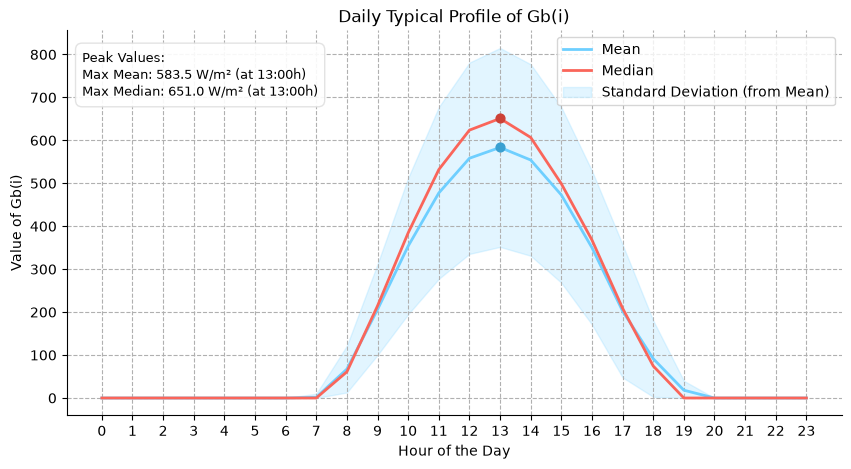

In [4]:
plot_daily_profile(processed_data, 'Gb(i)', 'Daily Typical Profile of Gb(i)', 'Hour of the Day', 'Value of Gb(i)')

This aggregate pattern blends the four seasons; it is broken down separately below.

## Seasonal pattern

In [5]:

seasonal_data = set_seasonal_profile(processed_data)
seasonal_data.head()

,P,Gb(i),Gd(i),Gr(i),H_sun,T2m,WS10m,v100,v10,d2m,...,skt,slhf,sp,sshf,ssrd,strd,tcc,tp,fdir,season
time,,,,,,,,,,,,,,,,,,,,,
2006-01-01 00:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.72,6.14,0.784286,0.346283,278.47076,...,279.50934,-48159.0,98977.516,32718.0,0.0,1111961.20,0.983185,0.000000e+00,0.0,Winter
2006-01-01 01:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.59,7.10,-0.314621,-0.198929,278.65588,...,280.03403,-56592.0,98955.700,65555.0,0.0,1066923.80,0.742828,4.768372e-07,0.0,Winter
2006-01-01 02:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.38,7.72,-1.158997,-0.526077,278.33942,...,280.30255,-56844.0,98924.625,79512.0,0.0,990057.94,0.971588,4.768372e-07,0.0,Winter
2006-01-01 03:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.21,7.79,-2.188812,-1.077423,277.91210,...,280.43246,-59865.0,98927.890,51426.0,0.0,1061742.10,0.986359,9.536743e-07,0.0,Winter
2006-01-01 04:00:00+01:00,0.0,0.0,0.0,0.0,0.0,12.03,7.79,-2.454651,-1.188324,278.11267,...,279.63710,-59507.0,98864.330,30478.0,0.0,1112992.60,0.934662,1.478195e-05,0.0,Winter


### Winter Pattern

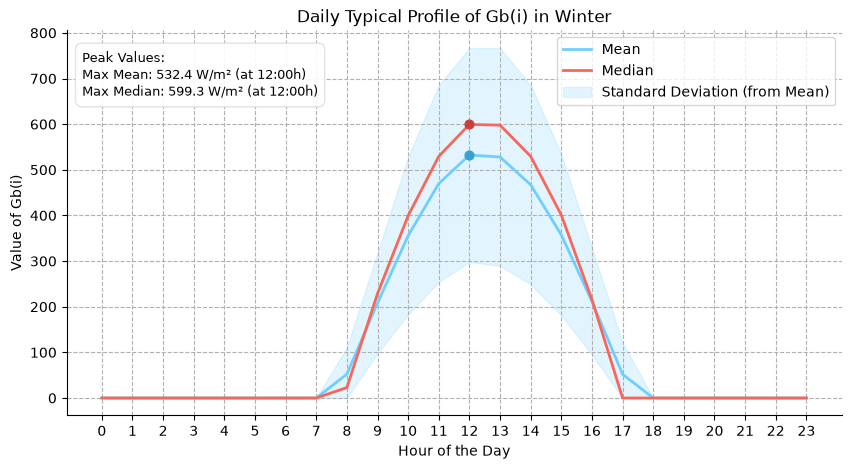

In [6]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Winter', 'Daily Typical Profile of Gb(i) in Winter', 'Hour of the Day', 'Value of Gb(i)')

### Spring Pattern

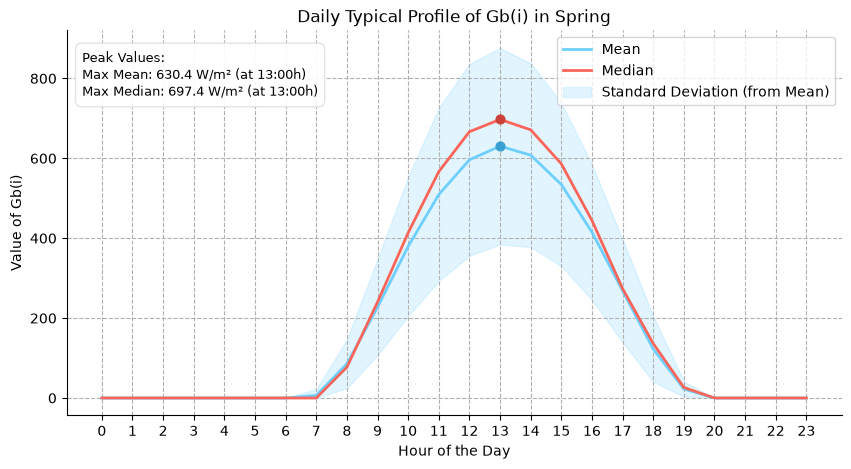

In [7]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Spring', 'Daily Typical Profile of Gb(i) in Spring', 'Hour of the Day', 'Value of Gb(i)')

### Summer Pattern

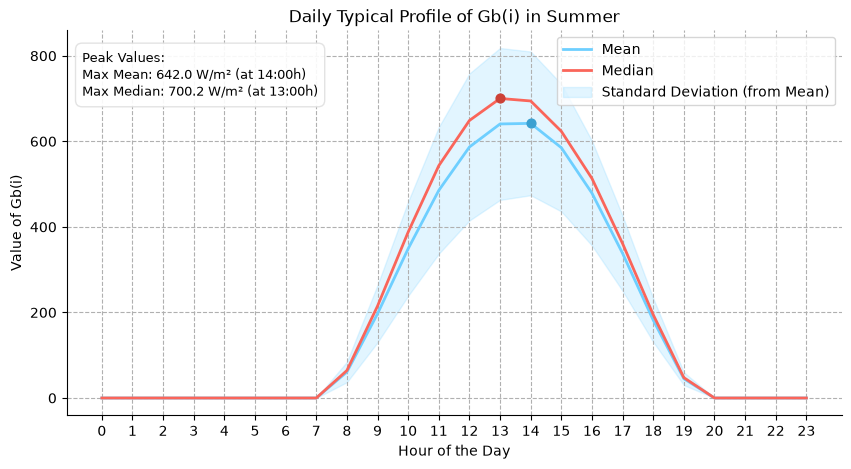

In [8]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Summer', 'Daily Typical Profile of Gb(i) in Summer', 'Hour of the Day', 'Value of Gb(i)')

### Autumn Pattern

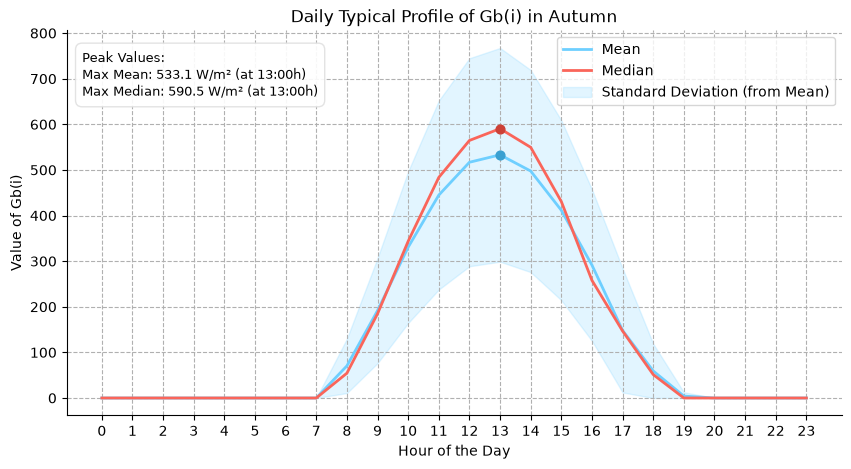

In [9]:
plot_daily_seasonal_profile(seasonal_data, 'Gb(i)', 'Autumn', 'Daily Typical Profile of Gb(i) in Autumn', 'Hour of the Day', 'Value of Gb(i)')

It is observed that `Gb(i)`, which is governed by solar geometry (sun position), reaches its maximum value in summer and spring but decreases in autumn and winter. The hours of peak intensity occur between 12:00 and 14:00.
It is also evident that the curve compresses during autumn and winter (as the days shorten). In winter, approximately 10 hours with positive Gb(i) values ​​are recorded, and in autumn, about 12; conversely, the curve extends in summer and spring (reaching approximately 13 hours).

## Relationship with meteorological variables

The correlation is calculated by station, but it still mixes different solar elevations throughout the day, so it likely underestimates the true strength of the relationship under comparable conditions.

### Summer Pattern

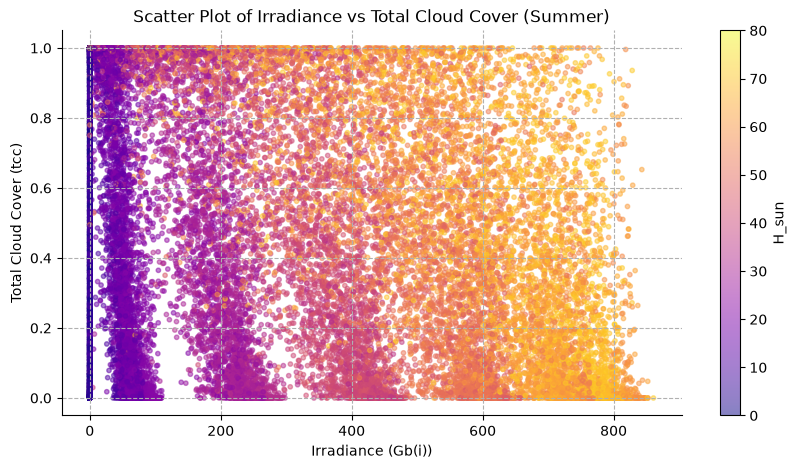

In [10]:
scatter_tcc_gbi_by_season(seasonal_data, 'Gb(i)','Irradiance','tcc','Total Cloud Cover', 'Summer')

In [11]:
pearson_corr_summer_data = seasonal_data[(seasonal_data['season'] == 'Summer') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('pearson')
pearson_corr_summer_data

,Gb(i),tcc
Gb(i),1.000000,-0.194419
tcc,-0.194419,1.000000


In [12]:
spearman_corr_summer_data = seasonal_data[(seasonal_data['season'] == 'Summer') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('spearman')
spearman_corr_summer_data

,Gb(i),tcc
Gb(i),1.00000,-0.17864
tcc,-0.17864,1.00000


### Autumn Pattern

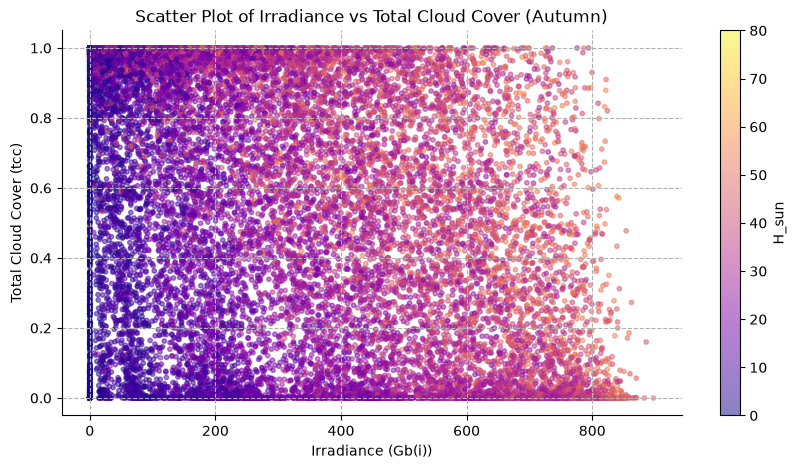

In [13]:
scatter_tcc_gbi_by_season(seasonal_data, 'Gb(i)','Irradiance','tcc','Total Cloud Cover', 'Autumn')

In [14]:
pearson_corr_autumn_data = seasonal_data[(seasonal_data['season'] == 'Autumn') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('pearson')
pearson_corr_autumn_data

,Gb(i),tcc
Gb(i),1.000000,-0.398131
tcc,-0.398131,1.000000


In [15]:
spearman_corr_autumn_data = seasonal_data[(seasonal_data['season'] == 'Autumn') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('spearman')
spearman_corr_autumn_data

,Gb(i),tcc
Gb(i),1.000000,-0.412453
tcc,-0.412453,1.000000


### Winter Pattern

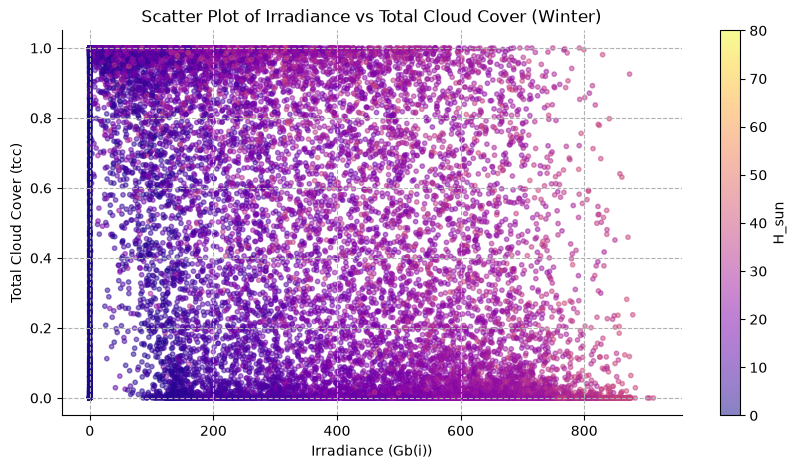

In [16]:
scatter_tcc_gbi_by_season(seasonal_data, 'Gb(i)','Irradiance','tcc','Total Cloud Cover', 'Winter')

In [17]:
pearson_corr_winter_data = seasonal_data[(seasonal_data['season'] == 'Winter') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('pearson')
pearson_corr_winter_data

,Gb(i),tcc
Gb(i),1.000000,-0.473207
tcc,-0.473207,1.000000


In [18]:
spearman_corr_winter_data = seasonal_data[(seasonal_data['season'] == 'Winter') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('spearman')
spearman_corr_winter_data

,Gb(i),tcc
Gb(i),1.00000,-0.48274
tcc,-0.48274,1.00000


### Spring Pattern

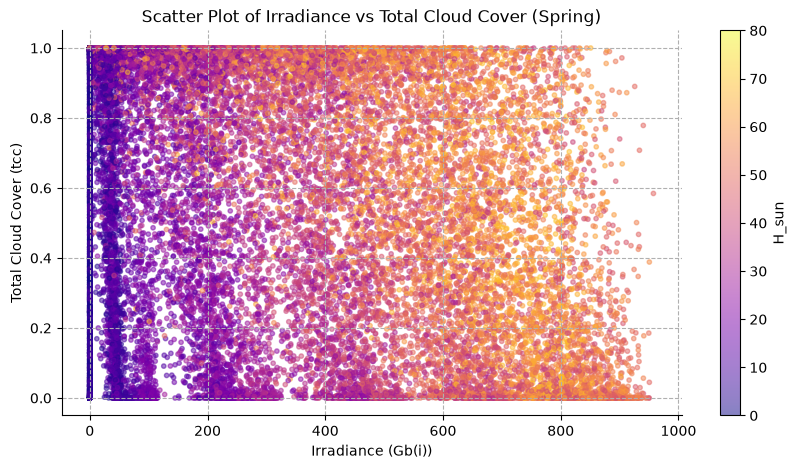

In [19]:
scatter_tcc_gbi_by_season(seasonal_data, 'Gb(i)','Irradiance','tcc','Total Cloud Cover', 'Spring')

In [20]:
pearson_corr_spring_data = seasonal_data[(seasonal_data['season'] == 'Spring') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('pearson')
pearson_corr_spring_data

,Gb(i),tcc
Gb(i),1.000000,-0.308502
tcc,-0.308502,1.000000


In [21]:
spearman_corr_spring_data = seasonal_data[(seasonal_data['season'] == 'Spring') & (seasonal_data['H_sun'] > 0)][['Gb(i)', 'tcc']].corr('spearman')
spearman_corr_spring_data

,Gb(i),tcc
Gb(i),1.00000,-0.31366
tcc,-0.31366,1.00000


The correlation is not stable across the year, it strengthens noticeably from summer toward winter; hourly visual analysis reveals a much clearer cloud-cover effect within each solar elevation band.

Summer: Pearson -0,19 / Spearman -0,18 (lowest)

Autumn: Pearson -0,40 / Spearman -0,41

Winter: Pearson -0,47 / Spearman -0,48 (highest)

Spring: Pearson -0,31 / Spearman -0,31

Note that the `H_sun` variable ranges lower in winter than in summer. A tighter `H_sun` range means a narrower confounding range. As there is less room for confusion in winter, the calculated coefficient comes closer to the actual relationship.

## Autocorrelation


Yesterday's autocorrelation: 0.865


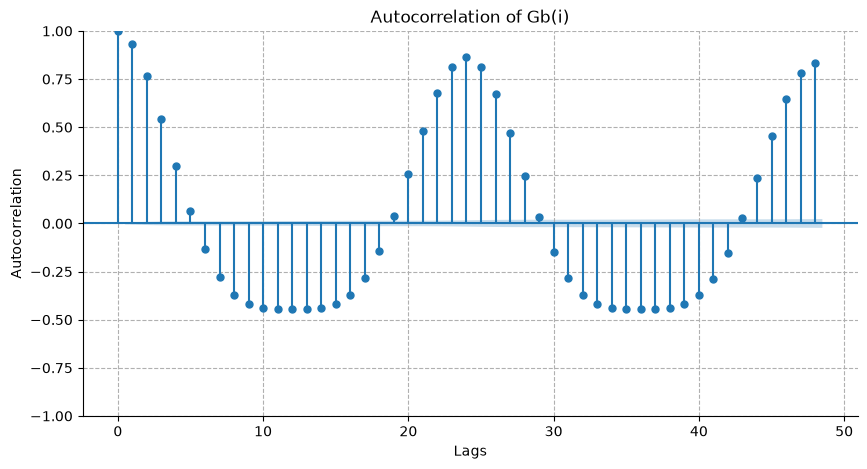

In [22]:

plot_autocorrelation(seasonal_data, 'Gb(i)')

This is the natural shape of the day/night cycle.

Yesterday's autocorrelation: 0.240


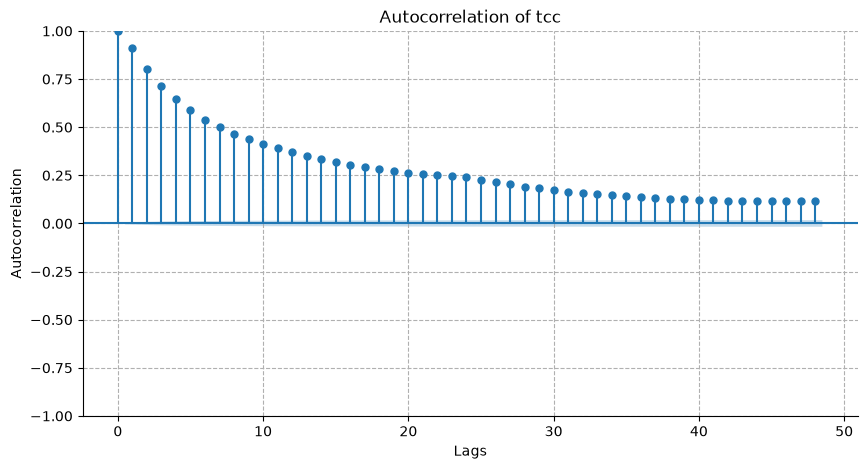

In [23]:
plot_autocorrelation(seasonal_data, 'tcc')

The memory is strong until ~7 hours and useful but weak until ~23 hours. Later than that it becomes residual.

**Lag 24 (same hour, yesterday)**

- `Gb(i)`:    0,865

- `tcc`:      0,240

## Conclusions


We are able to see that the seasons affect the daily light hours (~10 hours in Winter, ~13 in Summer) and therefore the `Gb(i)` (irradiance). 

The correlation cloud-irradiance is not stable, it ranges from -0,19 in Summer to -0,48 in Winter due to the `H_sun`.

The shape of the `Gb(i)` graph indicates that the majority of its 24-hour predictability is driven by the sun rather than meteorological conditions. It represents a form of *artificial memory*, a reflection of astronomy rather than weather. Cloud cover data (`tcc`) retain their memory (albeit with lower values) because they do not depend on the sun and are *real* memories.

We can effectively predict ~23 hours ahead, taking into count that the quality of the prediction will decrease over time.

A tighter `H_sun` range means a narrower confounding range. As there is less room for confusion in winter, the calculated coefficient comes closer to the actual relationship.